# StockJuste — Modèle de prédiction de la quantité vendue (par produit, mois et semaine)

**Objectif** : prédire la **quantité vendue** d'un produit pour une **semaine** d'un **mois** donné, afin d'aider le commerçant à éviter les ruptures et le gaspillage.

**Cible** : la colonne `Quantité prédite` du dataset est en réalité la **quantité vendue de la semaine** → renommée `quantite_vendue`.

**Plan du notebook**
1. Exploration
2. Nettoyage
3. Découpage du dataset (train / validation / test, **temporel**)
4. Preprocessing
5. Entraînement et validation
6. Test final

**Règles suivies** : le test n'est utilisé qu'**une seule fois** à la fin ; tout ce qui est « appris » (encodage, réglages) l'est sur le train / la validation uniquement ; aucun mélange aléatoire des données (série temporelle).

In [1]:
pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import ParameterSampler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})

SEED = 42
CSV_PATH = Path('dataset_supermarket_maroc.csv')   # même dossier que ce notebook

print('pandas', pd.__version__, '| xgboost', xgb.__version__, '| scikit-learn', sklearn.__version__)

pandas 2.2.3 | xgboost 3.4.1 | scikit-learn 1.8.0


---
# 1. Exploration

On commence par lire le fichier **tel quel** pour comprendre sa structure, ses types et ses éventuels problèmes, avant de toucher à quoi que ce soit.

In [4]:
# Le fichier commence par un BOM : encoding='utf-8-sig' évite un caractère invisible dans le nom de la 1re colonne
CSV_PATH = Path(r"C:\Users\Hp\StokeJuste\backend\app\features\prediction\dataset_supermarket_maroc.csv")
df_brut = pd.read_csv(CSV_PATH, encoding='utf-8-sig')
print('Forme :', df_brut.shape)
df_brut.head(10)

Forme : (1530, 12)


,Produit,Année / Mois / Semaine,Ventes S-1,Ventes S-2,Ventes S-3,Ventes S-4,Promotion,Prix,Nombre de lots,Date de production,Date de péremption,Quantité prédite
0,Ain Saiss,2023 / Janvier / S5,239,245,246,238,Oui,"35,59 MAD",10,2023-01-03,2023-04-03,302
1,Ain Saiss,2023 / Février / S1,302,239,245,246,Non,"41,87 MAD",9,2023-01-15,2023-04-15,181
2,Ain Saiss,2023 / Février / S2,181,302,239,245,Non,"41,87 MAD",9,2023-01-15,2023-04-15,255
3,Ain Saiss,2023 / Février / S3,255,181,302,239,Non,"41,87 MAD",11,2023-02-03,2023-05-04,237
4,Ain Saiss,2023 / Février / S4,237,255,181,302,Oui,"35,59 MAD",12,2023-02-04,2023-05-05,307
5,Ain Saiss,2023 / Mars / S1,307,237,255,181,Non,"41,87 MAD",11,2023-02-07,2023-05-08,300
6,Ain Saiss,2023 / Mars / S2,300,307,237,255,Non,"41,87 MAD",9,2023-02-23,2023-05-24,267
7,Ain Saiss,2023 / Mars / S3,267,300,307,237,Oui,"35,59 MAD",13,2023-02-23,2023-05-24,312
8,Ain Saiss,2023 / Mars / S4,312,267,300,307,Non,"41,87 MAD",10,2023-03-03,2023-06-01,278
9,Ain Saiss,2023 / Avril / S1,278,312,267,300,Oui,"35,59 MAD",14,2023-03-06,2023-06-04,358


In [5]:
print('--- Types ---')
print(df_brut.dtypes, '\n')
print('--- Valeurs manquantes ---')
print(df_brut.isna().sum(), '\n')
print('--- Lignes entièrement dupliquées :', df_brut.duplicated().sum())
print('--- Doublons (Produit, période) :', df_brut.duplicated(['Produit', 'Année / Mois / Semaine']).sum())
df_brut.describe().round(1)

--- Types ---
Produit                   object
Année / Mois / Semaine    object
Ventes S-1                 int64
Ventes S-2                 int64
Ventes S-3                 int64
Ventes S-4                 int64
Promotion                 object
Prix                      object
Nombre de lots             int64
Date de production        object
Date de péremption        object
Quantité prédite           int64
dtype: object 

--- Valeurs manquantes ---
Produit                   0
Année / Mois / Semaine    0
Ventes S-1                0
Ventes S-2                0
Ventes S-3                0
Ventes S-4                0
Promotion                 0
Prix                      0
Nombre de lots            0
Date de production        0
Date de péremption        0
Quantité prédite          0
dtype: int64 

--- Lignes entièrement dupliquées : 0
--- Doublons (Produit, période) : 0


,Ventes S-1,Ventes S-2,Ventes S-3,Ventes S-4,Nombre de lots,Quantité prédite
count,1530.0,1530.0,1530.0,1530.0,1530.0,1530.0
mean,175.4,175.5,175.4,175.4,8.8,175.4
std,62.1,62.0,62.0,62.0,2.6,62.1
min,74.0,74.0,74.0,74.0,3.0,74.0
25%,125.0,125.0,125.0,125.0,7.0,125.0
50%,164.0,164.0,164.0,164.0,9.0,164.0
75%,218.0,218.0,218.0,218.0,11.0,218.0
max,408.0,408.0,408.0,408.0,17.0,408.0


**Constats attendus** : les colonnes `Prix` (ex. `"35,59 MAD"`) et `Année / Mois / Semaine` (ex. `"2023 / Janvier / S5"`) sont du texte à convertir ; les dates sont lues comme du texte.

In [6]:
print('Produits :', df_brut['Produit'].nunique())
print(df_brut['Produit'].value_counts().to_string(), '\n')
print('Promotion :', df_brut['Promotion'].value_counts().to_dict())
print('Prix distincts par produit et promotion :')
display(df_brut.groupby(['Produit', 'Promotion'])['Prix'].nunique().unstack())
print('Valeurs de la période (3 premières) :', df_brut['Année / Mois / Semaine'].head(3).tolist())

Produits : 10
Produit
Ain Saiss                   153
Biscuits Merendina          153
Ciel                        153
Couscous Dari               153
Fromage La Vache Qui Rit    153
Huile de table Lesieur      153
Lait UHT Centrale           153
Sidi Ali                    153
Thé vert Sultan             153
Yaourt Jaouda               153 

Promotion : {'Non': 1198, 'Oui': 332}
Prix distincts par produit et promotion :


Promotion,Non,Oui
Produit,,
Ain Saiss,1,1
Biscuits Merendina,1,1
Ciel,1,1
Couscous Dari,1,1
Fromage La Vache Qui Rit,1,1
Huile de table Lesieur,1,1
Lait UHT Centrale,1,1
Sidi Ali,1,1
Thé vert Sultan,1,1


Valeurs de la période (3 premières) : ['2023 / Janvier / S5', '2023 / Février / S1', '2023 / Février / S2']


In [7]:
# Copie de travail, UNIQUEMENT pour l'exploration (le vrai nettoyage est fait en section 2)
MOIS = {'Janvier': 1, 'Février': 2, 'Mars': 3, 'Avril': 4, 'Mai': 5, 'Juin': 6, 'Juillet': 7,
        'Août': 8, 'Septembre': 9, 'Octobre': 10, 'Novembre': 11, 'Décembre': 12}

explo = df_brut.copy()
p = explo['Année / Mois / Semaine'].str.split(' / ', expand=True)
explo['annee'] = p[0].astype(int)
explo['mois_num'] = p[1].map(MOIS)
explo['semaine'] = p[2].str[1:].astype(int)
explo['prix'] = explo['Prix'].str.replace(' MAD', '', regex=False).str.replace(',', '.', regex=False).astype(float)
explo['promo'] = (explo['Promotion'] == 'Oui').astype(int)
explo = explo.rename(columns={'Quantité prédite': 'y', 'Produit': 'produit'})
explo['periode'] = pd.to_datetime(dict(year=explo.annee, month=explo.mois_num, day=1)) + pd.to_timedelta((explo.semaine - 1) * 7, unit='D')

print('Mois non reconnus :', explo['mois_num'].isna().sum())
print('Répartition par année :', explo['annee'].value_counts().sort_index().to_dict())
print('Répartition par semaine :', explo['semaine'].value_counts().sort_index().to_dict(), '(S5 = mois à 5 semaines)')
print('Semaines par produit :', explo.groupby('produit').size().unique())

Mois non reconnus : 0
Répartition par année : {2023: 480, 2024: 530, 2025: 520}
Répartition par semaine : {1: 350, 2: 350, 3: 350, 4: 350, 5: 130} (S5 = mois à 5 semaines)
Semaines par produit : [153]


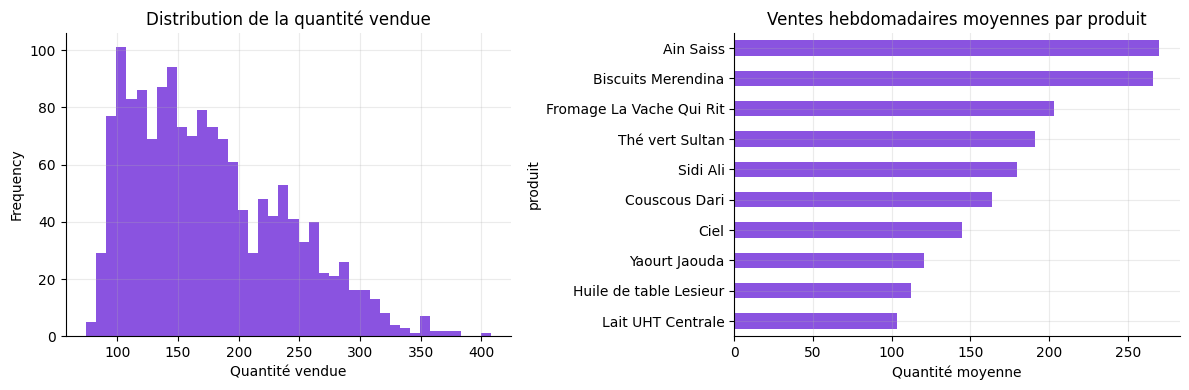

In [8]:
# Distribution de la cible et ventes moyennes par produit
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
explo['y'].plot.hist(bins=40, ax=ax[0], color='#6D28D9', alpha=.8)
ax[0].set_title('Distribution de la quantité vendue'); ax[0].set_xlabel('Quantité vendue')
explo.groupby('produit')['y'].mean().sort_values().plot.barh(ax=ax[1], color='#6D28D9', alpha=.8)
ax[1].set_title('Ventes hebdomadaires moyennes par produit'); ax[1].set_xlabel('Quantité moyenne')
plt.tight_layout(); plt.show()

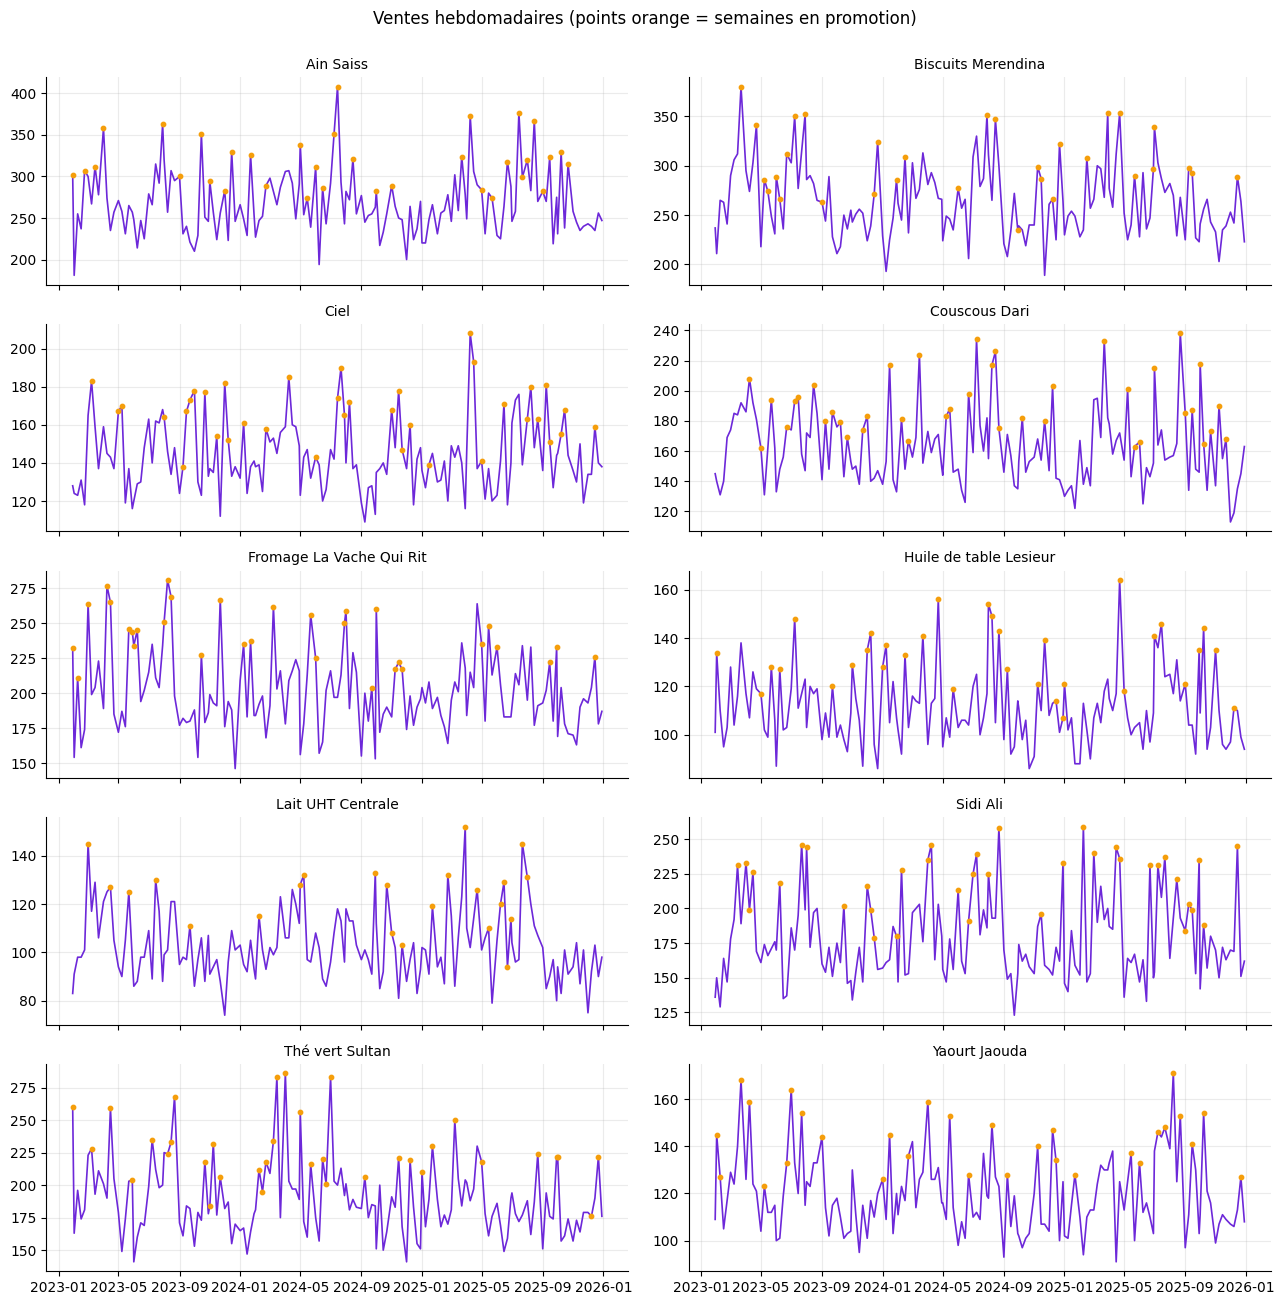

In [9]:
# Évolution des ventes dans le temps, un graphique par produit
produits = sorted(explo['produit'].unique())
fig, axes = plt.subplots(5, 2, figsize=(13, 13), sharex=True)
for ax, prod in zip(axes.ravel(), produits):
    d = explo[explo.produit == prod].sort_values('periode')
    ax.plot(d['periode'], d['y'], lw=1.2, color='#6D28D9')
    promo = d[d.promo == 1]
    ax.scatter(promo['periode'], promo['y'], s=10, color='#F59E0B', zorder=3)
    ax.set_title(prod, fontsize=10)
fig.suptitle('Ventes hebdomadaires (points orange = semaines en promotion)', y=1.0)
plt.tight_layout(); plt.show()

       count   mean  median
promo                      
0       1198  0.949   0.941
1        332  1.186   1.174

Hausse moyenne en promotion par produit (%) :
produit
Ain Saiss                   25.0
Biscuits Merendina          19.8
Ciel                        21.2
Couscous Dari               25.0
Fromage La Vache Qui Rit    25.9
Huile de table Lesieur      24.6
Lait UHT Centrale           24.5
Sidi Ali                    33.4
Thé vert Sultan             26.7
Yaourt Jaouda               24.8


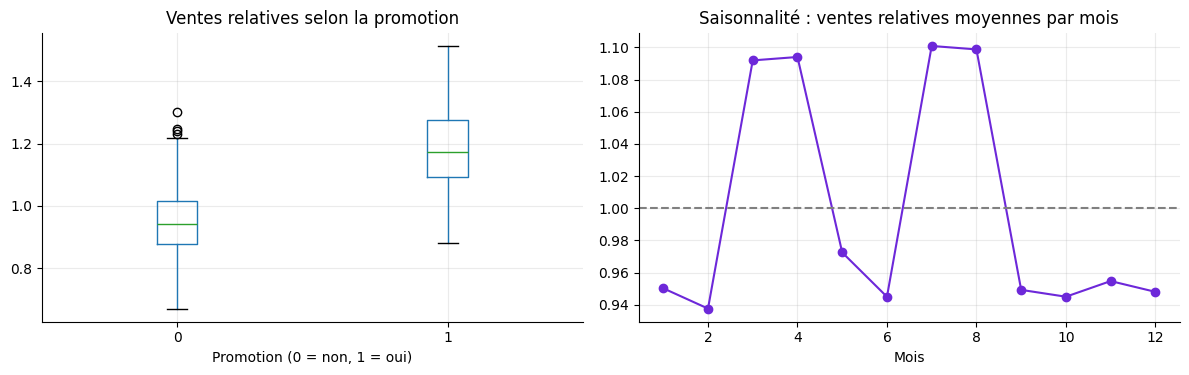

In [10]:
# Effet de la promotion : on normalise chaque produit par sa moyenne pour comparer les produits entre eux
explo['y_rel'] = explo['y'] / explo.groupby('produit')['y'].transform('mean')
print(explo.groupby('promo')['y_rel'].agg(['count', 'mean', 'median']).round(3))
print('\nHausse moyenne en promotion par produit (%) :')
tab = explo.groupby(['produit', 'promo'])['y'].mean().unstack()
print(((tab[1] / tab[0] - 1) * 100).round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
explo.boxplot(column='y_rel', by='promo', ax=ax[0]); ax[0].set_title('Ventes relatives selon la promotion'); ax[0].set_xlabel('Promotion (0 = non, 1 = oui)'); plt.suptitle('')
explo.groupby('mois_num')['y_rel'].mean().plot(marker='o', ax=ax[1], color='#6D28D9')
ax[1].set_title('Saisonnalité : ventes relatives moyennes par mois'); ax[1].set_xlabel('Mois'); ax[1].axhline(1, color='gray', ls='--')
plt.tight_layout(); plt.show()

y                 1.00
Ventes S-1        0.85
Ventes S-2        0.84
Ventes S-3        0.84
Ventes S-4        0.83
Nombre de lots    0.50
prix              0.03


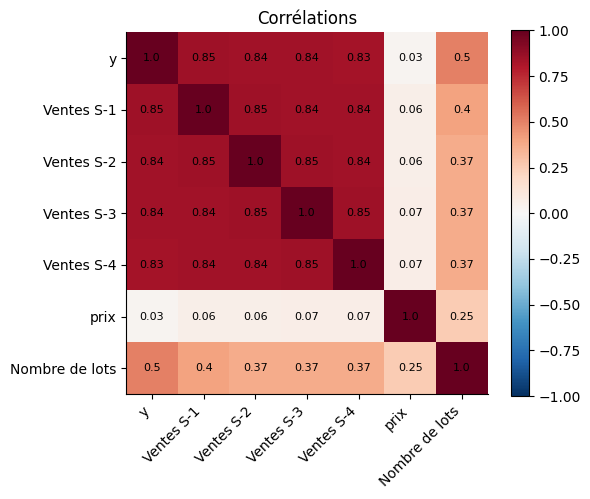

In [11]:
# Lien avec les ventes des semaines précédentes
cols = ['y', 'Ventes S-1', 'Ventes S-2', 'Ventes S-3', 'Ventes S-4', 'prix', 'Nombre de lots']
corr = explo[cols].corr().round(2)
print(corr['y'].sort_values(ascending=False).to_string())

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha='right')
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols); ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, corr.iloc[i, j], ha='center', va='center', fontsize=8)
plt.colorbar(im); ax.set_title('Corrélations'); plt.tight_layout(); plt.show()

In [12]:
# Vérification importante : « Ventes S-1 » d'une ligne = quantité vendue de la ligne précédente du même produit ?
explo = explo.sort_values(['produit', 'annee', 'mois_num', 'semaine']).reset_index(drop=True)
g = explo.groupby('produit')
coh = {f'S-{k}': (explo[f'Ventes S-{k}'] == g['y'].shift(k)).where(g['y'].shift(k).notna()).mean() for k in range(1, 5)}
print('Part de lignes où Ventes S-k = vente réelle k semaines avant :', {k: round(v, 3) for k, v in coh.items()})

Part de lignes où Ventes S-k = vente réelle k semaines avant : {'S-1': np.float64(1.0), 'S-2': np.float64(1.0), 'S-3': np.float64(1.0), 'S-4': np.float64(1.0)}


### Synthèse de l'exploration (à compléter avec vos observations)

- Le dataset contient **10 produits × 153 semaines** (2023 → 2025), sans valeur manquante ni doublon.
- La **promotion** augmente nettement les ventes, et le prix est plus bas pendant les promotions (le prix et la promotion sont donc liés).
- Les ventes des **semaines précédentes** sont les variables les plus liées à la cible.
- Les `Ventes S-1…S-4` d'une ligne sont les **vraies ventes** des lignes précédentes : un découpage **aléatoire** ferait fuiter le futur dans le train → on découpe **par période**.
- Le dataset est **simulé** : les scores obtenus seront à interpréter avec prudence.

---
# 2. Nettoyage

Une fonction `nettoyer()` regroupe toutes les étapes, pour qu'elles soient **reproductibles** (et réutilisables plus tard dans le backend).

In [13]:
# ============================================================
# NETTOYAGE, TRI CHRONOLOGIQUE, CONTRÔLES QUALITÉ ET EXPORT
# ============================================================

from pathlib import Path
import pandas as pd

MOIS = {
    'Janvier': 1, 'Février': 2, 'Mars': 3,
    'Avril': 4, 'Mai': 5, 'Juin': 6,
    'Juillet': 7, 'Août': 8, 'Septembre': 9,
    'Octobre': 10, 'Novembre': 11, 'Décembre': 12
}

def nettoyer(df_brut):
    """Nettoyer et trier le dataset chronologiquement."""

    df = df_brut.copy()

    # 1. Renommer les colonnes
    df = df.rename(columns={
        'Produit': 'produit',
        'Ventes S-1': 'ventes_s1',
        'Ventes S-2': 'ventes_s2',
        'Ventes S-3': 'ventes_s3',
        'Ventes S-4': 'ventes_s4',
        'Promotion': 'promotion',
        'Prix': 'prix',
        'Nombre de lots': 'nombre_lots',
        'Date de production': 'date_production',
        'Date de péremption': 'date_peremption',
        'Quantité prédite': 'quantite_vendue'
    })

    # 2. Extraire année, mois et semaine
    periode = df['Année / Mois / Semaine'].str.split(
        ' / ', expand=True
    )

    df['annee'] = periode[0].astype(int)
    df['mois'] = periode[1]
    df['mois_num'] = df['mois'].map(MOIS)
    df['semaine'] = periode[2].str.replace(
        'S', '', regex=False
    ).astype(int)

    df = df.drop(columns=['Année / Mois / Semaine'])

    # 3. Convertir le prix en numérique
    df['prix'] = (
        df['prix']
        .str.replace(' MAD', '', regex=False)
        .str.replace(',', '.', regex=False)
        .astype(float)
    )

    # 4. Encoder la promotion
    df['promotion'] = df['promotion'].map({
        'Oui': 1,
        'Non': 0
    })

    # 5. Convertir les dates
    df['date_production'] = pd.to_datetime(
        df['date_production']
    )

    df['date_peremption'] = pd.to_datetime(
        df['date_peremption']
    )

    # 6. Calculer la durée de vie du produit
    df['duree_vie_jours'] = (
        df['date_peremption'] - df['date_production']
    ).dt.days

    # 7. Calculer la moyenne des 4 semaines précédentes
    df['moyenne_4_semaines'] = df[
        ['ventes_s1', 'ventes_s2', 'ventes_s3', 'ventes_s4']
    ].mean(axis=1)

    # 8. Trier chronologiquement : année → mois → semaine
    df = df.sort_values(
        by=['annee', 'mois_num', 'semaine', 'produit'],
        ascending=[True, True, True, True]
    ).reset_index(drop=True)

    return df


# ============================================================
# APPLICATION DU NETTOYAGE
# ============================================================

df = nettoyer(df_brut)

# ============================================================
# CONTRÔLES QUALITÉ
# ============================================================

assert df.isna().sum().sum() == 0, "Valeurs manquantes"

assert not df.duplicated(
    ['produit', 'annee', 'mois_num', 'semaine']
).any(), "Doublons produit/période"

assert df['mois_num'].between(1, 12).all(), "Mois invalide"

assert df['semaine'].between(1, 5).all(), "Semaine invalide"

assert (
    df[['ventes_s1', 'ventes_s2', 'ventes_s3',
        'ventes_s4', 'quantite_vendue', 'nombre_lots']] >= 0
).all().all(), "Valeurs négatives"

assert (df['prix'] > 0).all(), "Prix invalide"

assert (
    df['date_peremption'] > df['date_production']
).all(), "Dates de production/péremption incohérentes"

assert df['promotion'].isin([0, 1]).all(), "Promotion invalide"

# Vérifier le tri chronologique
ordre = df[['annee', 'mois_num', 'semaine']]

assert ordre.reset_index(drop=True).equals(
    ordre.sort_values(
        ['annee', 'mois_num', 'semaine']
    ).reset_index(drop=True)
), "Tri chronologique incorrect"

print("Tous les contrôles qualité sont OK.")

# ============================================================
# ANALYSE DES VALEURS EXTRÊMES
# ============================================================

def nb_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1

    return (
        (s < q1 - 1.5 * iqr) |
        (s > q3 + 1.5 * iqr)
    ).sum()

print("\nValeurs extrêmes par produit :")

print(
    df.groupby('produit')['quantite_vendue']
    .apply(nb_outliers)
    .to_string()
)

# ============================================================
# VÉRIFICATION FINALE
# ============================================================

print("\nDimensions :", df.shape)

print("\nRépartition par année :")
print(df['annee'].value_counts().sort_index())

print("\nPremières périodes :")
display(
    df[['produit', 'annee', 'mois', 'semaine',
        'quantite_vendue']].head(15)
)

print("\nDernières périodes :")
display(
    df[['produit', 'annee', 'mois', 'semaine',
        'quantite_vendue']].tail(10)
)

# ============================================================
# EXPORT DU DATASET NETTOYÉ
# ============================================================

SORTIE = Path("dataset_stockjuste_nettoye.csv")

df.to_csv(
    SORTIE,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nDataset nettoyé enregistré : {SORTIE.resolve()}")

Tous les contrôles qualité sont OK.

Valeurs extrêmes par produit :
produit
Ain Saiss                   5
Biscuits Merendina          1
Ciel                        1
Couscous Dari               3
Fromage La Vache Qui Rit    3
Huile de table Lesieur      5
Lait UHT Centrale           3
Sidi Ali                    0
Thé vert Sultan             7
Yaourt Jaouda               3

Dimensions : (1530, 17)

Répartition par année :
annee
2023    480
2024    530
2025    520
Name: count, dtype: int64

Premières périodes :


,produit,annee,mois,semaine,quantite_vendue
0,Ain Saiss,2023,Janvier,5,302
1,Biscuits Merendina,2023,Janvier,5,237
2,Ciel,2023,Janvier,5,128
3,Couscous Dari,2023,Janvier,5,145
4,Fromage La Vache Qui Rit,2023,Janvier,5,232
5,Huile de table Lesieur,2023,Janvier,5,101
6,Lait UHT Centrale,2023,Janvier,5,83
7,Sidi Ali,2023,Janvier,5,136
8,Thé vert Sultan,2023,Janvier,5,260
9,Yaourt Jaouda,2023,Janvier,5,109



Dernières périodes :


,produit,annee,mois,semaine,quantite_vendue
1520,Ain Saiss,2025,Décembre,5,247
1521,Biscuits Merendina,2025,Décembre,5,223
1522,Ciel,2025,Décembre,5,138
1523,Couscous Dari,2025,Décembre,5,163
1524,Fromage La Vache Qui Rit,2025,Décembre,5,187
1525,Huile de table Lesieur,2025,Décembre,5,94
1526,Lait UHT Centrale,2025,Décembre,5,98
1527,Sidi Ali,2025,Décembre,5,162
1528,Thé vert Sultan,2025,Décembre,5,176
1529,Yaourt Jaouda,2025,Décembre,5,108



Dataset nettoyé enregistré : C:\Users\Hp\StokeJuste\backend\app\features\prediction\notebook\dataset_stockjuste_nettoye.csv


### Nettoyage et préparation des données

Les opérations suivantes ont été appliquées :

1. **Renommage des colonnes** : uniformisation des noms et renommage de la cible `Quantité prédite` en `quantite_vendue`.
2. **Transformation des variables temporelles** : extraction de l'année, du mois et de la semaine, avec conversion du mois en valeur numérique.
3. **Conversion du prix** : suppression de « MAD » et conversion en nombre décimal.
4. **Encodage de la promotion** : Oui = 1 et Non = 0.
5. **Conversion des dates** : transformation des dates de production et de péremption au format datetime.
6. **Création de variables** : durée de vie du produit et moyenne des ventes des quatre semaines précédentes.
7. **Tri chronologique croissant** : année → mois → semaine → produit, pour préparer le découpage temporel.
8. **Contrôles qualité** : vérification des valeurs manquantes, doublons, valeurs négatives, prix, dates et périodes invalides.
9. **Détection des valeurs extrêmes** : identification par produit avec la méthode IQR, sans suppression automatique.
10. **Exportation** : enregistrement du dataset nettoyé au format CSV.

In [14]:
print("Les 5 premières lignes du dataset nettoyé :")
display(df.head(5))

Les 5 premières lignes du dataset nettoyé :


,produit,ventes_s1,ventes_s2,ventes_s3,ventes_s4,promotion,prix,nombre_lots,date_production,date_peremption,quantite_vendue,annee,mois,mois_num,semaine,duree_vie_jours,moyenne_4_semaines
0,Ain Saiss,239,245,246,238,1,35.59,10,2023-01-03,2023-04-03,302,2023,Janvier,1,5,90,242.00
1,Biscuits Merendina,220,241,240,238,0,33.12,9,2023-01-15,2023-07-14,237,2023,Janvier,1,5,180,234.75
2,Ciel,124,135,134,148,0,45.37,5,2023-01-09,2023-02-08,128,2023,Janvier,1,5,30,135.25
3,Couscous Dari,145,215,171,165,0,21.49,8,2023-01-09,2023-07-08,145,2023,Janvier,1,5,180,174.00
4,Fromage La Vache Qui Rit,184,219,213,165,1,44.87,11,2023-01-07,2023-07-06,232,2023,Janvier,1,5,180,195.25


In [15]:
import pandas as pd
from pathlib import Path

# Chemin du dataset nettoyé
CSV_PATH = Path("dataset_stockjuste_nettoye.csv")

# Charger le dataset
df = pd.read_csv(CSV_PATH)

# Colonnes à supprimer
colonnes_supprimer = [
    'mois',
    'date_production',
    'date_peremption'
]

# Supprimer les colonnes
df = df.drop(columns=colonnes_supprimer, errors='ignore')

# Écraser le même fichier CSV
df.to_csv(CSV_PATH, index=False, encoding='utf-8-sig')

# Vérification
print("Dataset mis à jour avec succès !")
print("Dimensions :", df.shape)
print("Colonnes restantes :", df.columns.tolist())

display(df.head(5))

Dataset mis à jour avec succès !
Dimensions : (1530, 14)
Colonnes restantes : ['produit', 'ventes_s1', 'ventes_s2', 'ventes_s3', 'ventes_s4', 'promotion', 'prix', 'nombre_lots', 'quantite_vendue', 'annee', 'mois_num', 'semaine', 'duree_vie_jours', 'moyenne_4_semaines']


,produit,ventes_s1,ventes_s2,ventes_s3,ventes_s4,promotion,prix,nombre_lots,quantite_vendue,annee,mois_num,semaine,duree_vie_jours,moyenne_4_semaines
0,Ain Saiss,239,245,246,238,1,35.59,10,302,2023,1,5,90,242.00
1,Biscuits Merendina,220,241,240,238,0,33.12,9,237,2023,1,5,180,234.75
2,Ciel,124,135,134,148,0,45.37,5,128,2023,1,5,30,135.25
3,Couscous Dari,145,215,171,165,0,21.49,8,145,2023,1,5,180,174.00
4,Fromage La Vache Qui Rit,184,219,213,165,1,44.87,11,232,2023,1,5,180,195.25


---
# 3. Découpage du dataset (train / validation / test)

Il s'agit d'une **série temporelle** : on découpe **par période**, jamais au hasard.

| Jeu | Période | Rôle |
|---|---|---|
| **Train** | janvier 2023 → juin 2024 | apprendre le modèle |
| **Validation** | juillet 2024 → décembre 2024 | choisir les hyperparamètres, arrêter l'entraînement |
| **Test** | année 2025 | évaluation finale, **utilisé une seule fois** |

Chaque jeu contient les 10 produits.

In [20]:
import pandas as pd
from pathlib import Path

# Charger le dataset nettoyé
CSV_PATH = Path("dataset_stockjuste_nettoye.csv")
df = pd.read_csv(CSV_PATH)

# 1. Trier chronologiquement
df = df.sort_values(
    ['annee', 'mois_num', 'semaine', 'produit']
).reset_index(drop=True)

# 2. Définir les périodes
is_train = (
    (df['annee'] == 2023) |
    ((df['annee'] == 2024) & (df['mois_num'] <= 6))
)

is_val = (
    (df['annee'] == 2024) &
    (df['mois_num'] >= 7)
)

is_test = df['annee'] == 2025

# 3. Effectuer le découpage
train_df = df[is_train].copy()
val_df = df[is_val].copy()
test_df = df[is_test].copy()

# 4. Vérifier qu'aucune ligne n'est oubliée
assert len(train_df) + len(val_df) + len(test_df) == len(df)

# Vérifier qu'aucune ligne n'appartient à plusieurs ensembles
assert ((is_train.astype(int) +
         is_val.astype(int) +
         is_test.astype(int)) == 1).all()

# 5. Vérifier l'ordre chronologique
def periode_min_max(data):
    periodes = list(zip(
        data['annee'],
        data['mois_num'],
        data['semaine']
    ))
    return min(periodes), max(periodes)

assert (
    periode_min_max(train_df)[1]
    < periode_min_max(val_df)[0]
    <= periode_min_max(val_df)[1]
    < periode_min_max(test_df)[0]
)

# 6. Résumé du découpage
resume = pd.DataFrame({
    'lignes': [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    'part (%)': [
        round(100 * len(x) / len(df), 1)
        for x in (train_df, val_df, test_df)
    ],
    'début': [
        f"{periode_min_max(x)[0][0]}-M{periode_min_max(x)[0][1]:02d}-S{periode_min_max(x)[0][2]}"
        for x in (train_df, val_df, test_df)
    ],
    'fin': [
        f"{periode_min_max(x)[1][0]}-M{periode_min_max(x)[1][1]:02d}-S{periode_min_max(x)[1][2]}"
        for x in (train_df, val_df, test_df)
    ],
    'produits': [
        x['produit'].nunique()
        for x in (train_df, val_df, test_df)
    ]
}, index=['Train', 'Validation', 'Test'])

print("Découpage temporel effectué avec succès !")
display(resume)

Découpage temporel effectué avec succès !


,lignes,part (%),début,fin,produits
Train,740,48.4,2023-M01-S5,2024-M06-S4,10
Validation,270,17.6,2024-M07-S1,2024-M12-S5,10
Test,520,34.0,2025-M01-S1,2025-M12-S5,10


---
# 4. Preprocessing

Deux types de transformations, à ne pas confondre :

1. **Création de variables sans paramètres appris** (moyenne des 4 semaines, durée de vie…) : appliquées de la même façon à chaque jeu.
2. **Transformations qui apprennent quelque chose** (encodage du produit) : **ajustées sur le train uniquement**, puis appliquées à la validation et au test → pas de fuite de données.

Pas de normalisation pour XGBoost (les arbres n'en ont pas besoin).

In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline

# Variables catégorielles
CAT = ['produit']

# Variables numériques
NUM = [
    'ventes_s1',
    'ventes_s2',
    'ventes_s3',
    'ventes_s4',
    'promotion',
    'prix',
    'nombre_lots',
    'annee',
    'mois_num',
    'semaine',
    'moyenne_4_semaines',
    'tendance',
    'duree_vie_jours'
]

FEATURES = CAT + NUM
TARGET = 'quantite_vendue'

# Preprocessing pour XGBoost
preprocessor_xgb = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ), CAT),

        ('num', 'passthrough', NUM)
    ]
)

# Preprocessing pour Ridge
preprocessor_ridge = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ), CAT),

        ('num', StandardScaler(), NUM)
    ]
)

print("Preprocessing configuré avec succès !")

Preprocessing configuré avec succès !


In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Preprocessing XGBoost
preprocessor_xgb = ColumnTransformer([
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ), CAT),

    ('num', 'passthrough', NUM)
])

# Apprendre les transformations uniquement sur Train
X_train_xgb = preprocessor_xgb.fit_transform(X_train)

# Appliquer les mêmes transformations
X_val_xgb = preprocessor_xgb.transform(X_val)
X_test_xgb = preprocessor_xgb.transform(X_test)

# Vérification
print("Preprocessing XGBoost terminé !")
print("Train :", X_train_xgb.shape)
print("Validation :", X_val_xgb.shape)
print("Test :", X_test_xgb.shape)

Preprocessing XGBoost terminé !
Train : (740, 23)
Validation : (270, 23)
Test : (520, 23)


---
# 5. Entraînement et validation

### 5.1 Métriques et modèles de référence

Un modèle n'a de valeur que s'il **bat des références simples**. On calcule donc d'abord :
- **Naïf** : prédire les ventes de la semaine précédente (S-1) ;
- **Moyenne 4 semaines** : prédire la moyenne des 4 dernières semaines ;
- **Régression linéaire (Ridge)** : un modèle simple.

Métriques : **MAE** (erreur moyenne en unités), **RMSE** (pénalise les grosses erreurs), **R²**, **WAPE** (erreur totale en % des ventes).

In [26]:
# Fonction de feature engineering
def creer_variables(df):
    d = df.copy()

    # Moyenne des ventes des 4 semaines précédentes
    d['moyenne_4_semaines'] = d[
        ['ventes_s1', 'ventes_s2', 'ventes_s3', 'ventes_s4']
    ].mean(axis=1)

    # Tendance des ventes
    d['tendance'] = d['ventes_s1'] - d['ventes_s4']

    return d


# Appliquer aux trois ensembles
train_f = creer_variables(train_df)
val_f = creer_variables(val_df)
test_f = creer_variables(test_df)

print("Feature engineering terminé !")
print("Train :", train_f.shape)
print("Validation :", val_f.shape)
print("Test :", test_f.shape)

Feature engineering terminé !
Train : (740, 15)
Validation : (270, 15)
Test : (520, 15)


In [27]:
# Séparer les variables explicatives (X) et la cible (y)

X_train = train_f[FEATURES].copy()
X_val = val_f[FEATURES].copy()
X_test = test_f[FEATURES].copy()

y_train = train_f[TARGET].copy()
y_val = val_f[TARGET].copy()
y_test = test_f[TARGET].copy()

# Vérification
print("Train :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

Train : (740, 14) (740,)
Validation : (270, 14) (270,)
Test : (520, 14) (520,)


In [28]:
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge

SEED = 42

# Fonction d'évaluation
def evaluer(y_vrai, y_pred):
    y_vrai = np.asarray(y_vrai)
    y_pred = np.asarray(y_pred)

    return {
        'MAE': mean_absolute_error(y_vrai, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_vrai, y_pred)),
        'R2': r2_score(y_vrai, y_pred),
        'WAPE_%': (
            100 * np.abs(y_vrai - y_pred).sum()
            / np.abs(y_vrai).sum()
            if np.abs(y_vrai).sum() != 0 else np.nan
        )
    }

# Modèle Ridge avec preprocessing intégré
ridge = make_pipeline(
    preprocessor_ridge,
    Ridge(alpha=1.0)
)

# Entraînement sur Train
ridge.fit(X_train, y_train)

# Comparaison sur Validation
resultats_val = pd.DataFrame({
    'Naïf (S-1)': evaluer(y_val, val_f['ventes_s1']),
    'Moyenne 4 semaines': evaluer(y_val, val_f['moyenne_4_semaines']),
    'Ridge': evaluer(y_val, ridge.predict(X_val))
}).T.round(2)

display(resultats_val)

,MAE,RMSE,R2,WAPE_%
Naïf (S-1),25.58,34.05,0.71,14.63
Moyenne 4 semaines,21.79,29.89,0.77,12.46
Ridge,13.40,17.84,0.92,7.67


### 5.2 XGBoost avec réglages par défaut raisonnables

On utilise l'**arrêt anticipé** (`early_stopping_rounds`) : l'entraînement s'arrête quand l'erreur de validation cesse de s'améliorer, ce qui évite le sur-apprentissage.

In [32]:
import xgboost as xgb

modele_base = xgb.XGBRegressor(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    eval_metric='mae',
    early_stopping_rounds=50,
    random_state=SEED,
    n_jobs=-1
)

# Entraînement avec Early Stopping
modele_base.fit(
    X_train_xgb,
    y_train,
    eval_set=[(X_val_xgb, y_val)],
    verbose=False
)

print("Nombre d'arbres retenu :", modele_base.best_iteration + 1)

# Prédictions sur Validation
y_pred_base = modele_base.predict(X_val_xgb)

# Ajouter les résultats
resultats_val.loc['XGBoost (base)'] = evaluer(y_val, y_pred_base)

display(resultats_val.round(2))

Nombre d'arbres retenu : 283


,MAE,RMSE,R2,WAPE_%
Naïf (S-1),25.58,34.05,0.71,14.63
Moyenne 4 semaines,21.79,29.89,0.77,12.46
Ridge,13.40,17.84,0.92,7.67
XGBoost (base),12.45,16.51,0.93,7.12


### 5.3 Réglage des hyperparamètres

Recherche aléatoire sur **40 combinaisons**, chacune évaluée sur la **validation** (jamais sur le test). On évite volontairement la validation croisée classique : mélanger des périodes casserait l'ordre du temps.

In [33]:
from sklearn.model_selection import ParameterSampler

# Espace de recherche
espace = {
    'max_depth': [2, 3, 4, 5, 6],
    'learning_rate': [0.02, 0.03, 0.05, 0.08, 0.1],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5, 10],
    'reg_lambda': [0.5, 1, 2, 5, 10],
    'gamma': [0, 0.5, 1, 2]
}

essais = []

# Tester 40 combinaisons
for i, params in enumerate(
    ParameterSampler(espace, n_iter=40, random_state=SEED),
    start=1
):
    m = xgb.XGBRegressor(
        n_estimators=2000,
        objective='reg:squarederror',
        eval_metric='mae',
        early_stopping_rounds=50,
        random_state=SEED,
        n_jobs=-1,
        **params
    )

    # Entraînement
    m.fit(
        X_train_xgb,
        y_train,
        eval_set=[(X_val_xgb, y_val)],
        verbose=False
    )

    # Évaluation
    y_pred = m.predict(X_val_xgb)

    essais.append({
        **params,
        'n_arbres': m.best_iteration + 1,
        'MAE_val': mean_absolute_error(y_val, y_pred)
    })

    print(f"Essai {i}/40 terminé")

# Classer les essais selon la MAE
essais = (
    pd.DataFrame(essais)
    .sort_values('MAE_val')
    .reset_index(drop=True)
)

print("\nLes 5 meilleures configurations :")
display(essais.head(5).round(3))

Essai 1/40 terminé
Essai 2/40 terminé
Essai 3/40 terminé
Essai 4/40 terminé
Essai 5/40 terminé
Essai 6/40 terminé
Essai 7/40 terminé
Essai 8/40 terminé
Essai 9/40 terminé
Essai 10/40 terminé
Essai 11/40 terminé
Essai 12/40 terminé
Essai 13/40 terminé
Essai 14/40 terminé
Essai 15/40 terminé
Essai 16/40 terminé
Essai 17/40 terminé
Essai 18/40 terminé
Essai 19/40 terminé
Essai 20/40 terminé
Essai 21/40 terminé
Essai 22/40 terminé
Essai 23/40 terminé
Essai 24/40 terminé
Essai 25/40 terminé
Essai 26/40 terminé
Essai 27/40 terminé
Essai 28/40 terminé
Essai 29/40 terminé
Essai 30/40 terminé
Essai 31/40 terminé
Essai 32/40 terminé
Essai 33/40 terminé
Essai 34/40 terminé
Essai 35/40 terminé
Essai 36/40 terminé
Essai 37/40 terminé
Essai 38/40 terminé
Essai 39/40 terminé
Essai 40/40 terminé

Les 5 meilleures configurations :


,subsample,reg_lambda,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree,n_arbres,MAE_val
0,0.7,1.0,3,3,0.08,0.5,1.0,596,12.245
1,0.7,1.0,1,3,0.08,0.0,1.0,411,12.266
2,0.6,5.0,3,4,0.03,0.0,0.9,439,12.438
3,1.0,1.0,3,6,0.05,0.0,1.0,151,12.442
4,1.0,5.0,5,4,0.10,2.0,0.7,178,12.519


In [35]:
# 1. Récupérer la meilleure configuration
meilleurs = essais.iloc[0]

params_finaux = {
    k: (
        int(meilleurs[k])
        if k in ('max_depth', 'min_child_weight')
        else float(meilleurs[k])
    )
    for k in espace
}

n_arbres = int(meilleurs['n_arbres'])

print("Hyperparamètres retenus :", params_finaux)
print("Nombre d'arbres optimal :", n_arbres)

# 2. Créer le modèle optimisé
modele = xgb.XGBRegressor(
    n_estimators=n_arbres,
    objective='reg:squarederror',
    eval_metric='mae',
    random_state=SEED,
    n_jobs=-1,
    **params_finaux
)

# 3. Entraîner avec les données prétraitées
modele.fit(
    X_train_xgb,
    y_train,
    verbose=False
)

# 4. Prédictions sur Validation
y_pred_final = modele.predict(X_val_xgb)

# 5. Évaluation
resultats_val.loc['XGBoost (réglé)'] = evaluer(
    y_val,
    y_pred_final
)

# 6. Comparaison des modèles
print("Comparaison des performances sur Validation :")
display(resultats_val.round(2))

Hyperparamètres retenus : {'max_depth': 3, 'learning_rate': 0.08, 'subsample': 0.7, 'colsample_bytree': 1.0, 'min_child_weight': 3, 'reg_lambda': 1.0, 'gamma': 0.5}
Nombre d'arbres optimal : 596
Comparaison des performances sur Validation :


,MAE,RMSE,R2,WAPE_%
Naïf (S-1),25.58,34.05,0.71,14.63
Moyenne 4 semaines,21.79,29.89,0.77,12.46
Ridge,13.40,17.84,0.92,7.67
XGBoost (base),12.45,16.51,0.93,7.12
XGBoost (réglé),12.25,16.36,0.93,7.01


Que signifient ces résultats ?
- MAE = 12,25 : le modèle se trompe en moyenne d'environ 12 unités vendues par prédiction hebdomadaire.
- RMSE = 16,36 : les erreurs importantes sont davantage pénalisées ; cette valeur reste relativement proche de la MAE.
- R² = 0,93 : le modèle explique environ 93 % de la variabilité des quantités vendues sur la validation.
- WAPE = 7,01 % : les erreurs absolues cumulées représentent environ 7 % des ventes réelles cumulées.

### 5.4 Diagnostic sur la validation

On regarde la courbe d'apprentissage (surapprentissage ?), puis l'erreur par produit.

In [37]:
# Récupérer la meilleure configuration
meilleurs = essais.iloc[0]

params_finaux = {
    k: (
        int(meilleurs[k])
        if k in ('max_depth', 'min_child_weight')
        else float(meilleurs[k])
    )
    for k in espace
}

n_arbres = int(meilleurs['n_arbres'])

print("Hyperparamètres retenus :", params_finaux)
print("Nombre d'arbres optimal :", n_arbres)

# Créer le modèle optimisé
modele = xgb.XGBRegressor(
    n_estimators=n_arbres,
    objective='reg:squarederror',
    eval_metric='mae',
    random_state=SEED,
    n_jobs=-1,
    **params_finaux
)

# Entraînement avec suivi des performances
modele.fit(
    X_train_xgb,
    y_train,
    eval_set=[
        (X_train_xgb, y_train),
        (X_val_xgb, y_val)
    ],
    verbose=False
)

# Prédictions sur Validation
y_pred_final = modele.predict(X_val_xgb)

# Évaluation
resultats_val.loc['XGBoost (réglé)'] = evaluer(
    y_val,
    y_pred_final
)

display(resultats_val.round(2))

Hyperparamètres retenus : {'max_depth': 3, 'learning_rate': 0.08, 'subsample': 0.7, 'colsample_bytree': 1.0, 'min_child_weight': 3, 'reg_lambda': 1.0, 'gamma': 0.5}
Nombre d'arbres optimal : 596


,MAE,RMSE,R2,WAPE_%
Naïf (S-1),25.58,34.05,0.71,14.63
Moyenne 4 semaines,21.79,29.89,0.77,12.46
Ridge,13.40,17.84,0.92,7.67
XGBoost (base),12.45,16.51,0.93,7.12
XGBoost (réglé),12.25,16.36,0.93,7.01


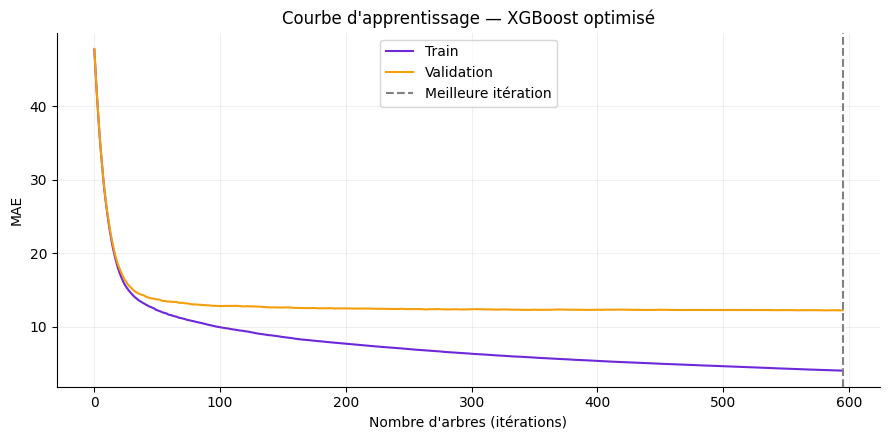

Meilleure itération : 596
MAE Train finale : 4.05
MAE Validation finale : 12.25


In [38]:
import matplotlib.pyplot as plt
import numpy as np

# Récupérer l'historique d'entraînement
hist = modele.evals_result()

mae_train = hist['validation_0']['mae']
mae_val = hist['validation_1']['mae']

# Identifier la meilleure itération sur Validation
meilleure_iteration = np.argmin(mae_val)

# Tracer la courbe
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    mae_train,
    label='Train',
    color='#6D28D9'
)

ax.plot(
    mae_val,
    label='Validation',
    color='#F59E0B'
)

ax.axvline(
    meilleure_iteration,
    color='gray',
    linestyle='--',
    label='Meilleure itération'
)

ax.set_xlabel("Nombre d'arbres (itérations)")
ax.set_ylabel("MAE")
ax.set_title("Courbe d'apprentissage — XGBoost optimisé")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("Meilleure itération :", meilleure_iteration + 1)
print("MAE Train finale :", round(mae_train[-1], 2))
print("MAE Validation finale :", round(mae_val[-1], 2))

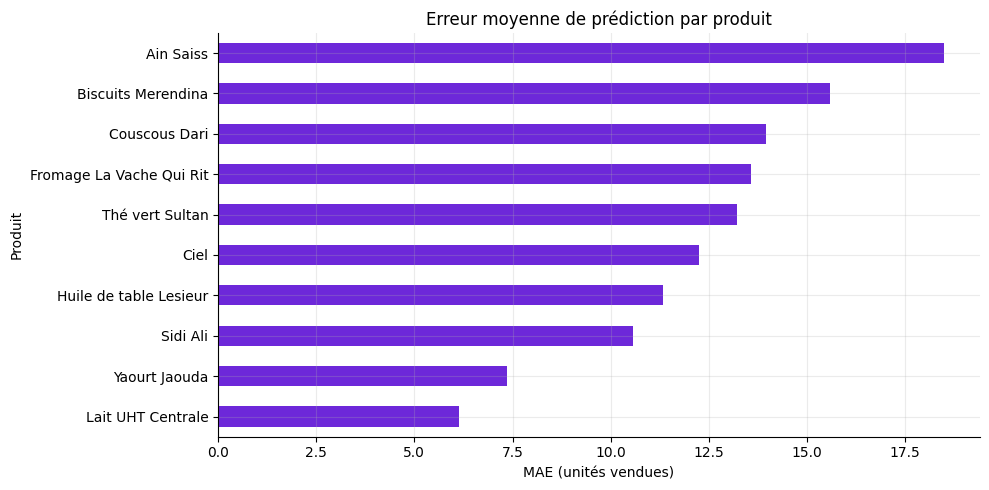

,MAE
produit,
Ain Saiss,18.48
Biscuits Merendina,15.57
Couscous Dari,13.97
Fromage La Vache Qui Rit,13.58
Thé vert Sultan,13.21
Ciel,12.24
Huile de table Lesieur,11.33
Sidi Ali,10.57
Yaourt Jaouda,7.36


In [39]:
# Comparaison des ventes réelles et prédites
diagnostic = val_f[['produit', 'quantite_vendue']].copy()

diagnostic['prediction'] = y_pred_final

diagnostic['erreur_absolue'] = abs(
    diagnostic['quantite_vendue'] - diagnostic['prediction']
)

# MAE par produit
erreur_produit = (
    diagnostic.groupby('produit')['erreur_absolue']
    .mean()
    .sort_values(ascending=False)
)

# Visualisation
plt.figure(figsize=(10, 5))

erreur_produit.plot(
    kind='barh',
    color='#6D28D9'
)

plt.xlabel('MAE (unités vendues)')
plt.ylabel('Produit')
plt.title('Erreur moyenne de prédiction par produit')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

display(erreur_produit.round(2).to_frame('MAE'))

---
# 6. Test final

Le **test (2025)** n'a servi à **aucun** choix jusqu'ici. On l'utilise **une seule fois**, avec le modèle réglé en section 5. Si les résultats sont mauvais, on ne retouche pas les réglages « pour améliorer le test » : ce serait de la triche.


========== RÉSULTATS SUR TEST 2025 ==========


,MAE,RMSE,R2,WAPE_%
Naïf (S-1),24.90,33.87,0.70,14.26
Moyenne 4 semaines,20.23,26.90,0.81,11.59
Ridge,13.88,18.04,0.91,7.95
XGBoost (base),12.32,16.65,0.93,7.06
XGBoost (réglé),12.53,16.69,0.93,7.18



========== VALIDATION VS TEST ==========


,Validation,Test
MAE,12.25,12.53
RMSE,16.36,16.69
R2,0.93,0.93
WAPE_%,7.01,7.18


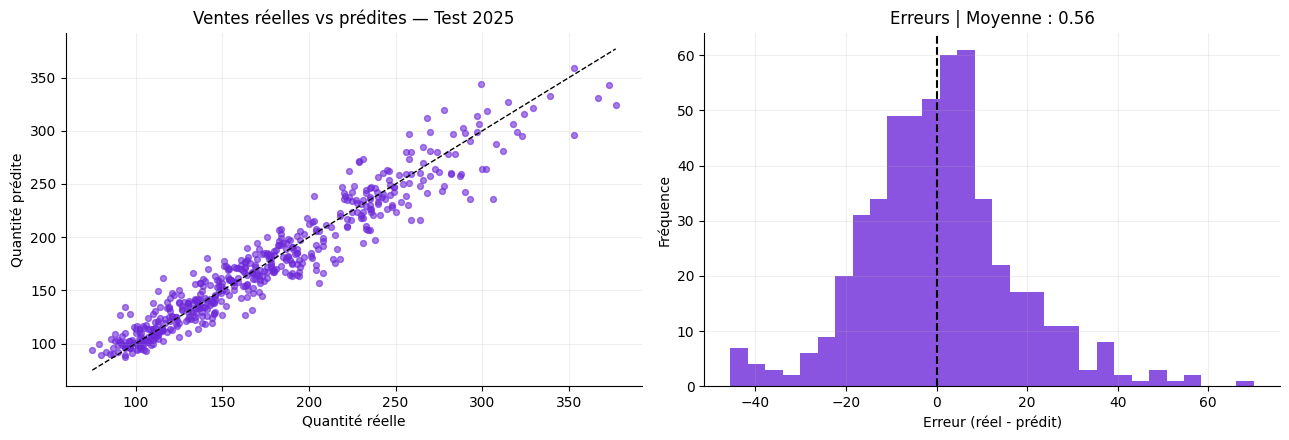

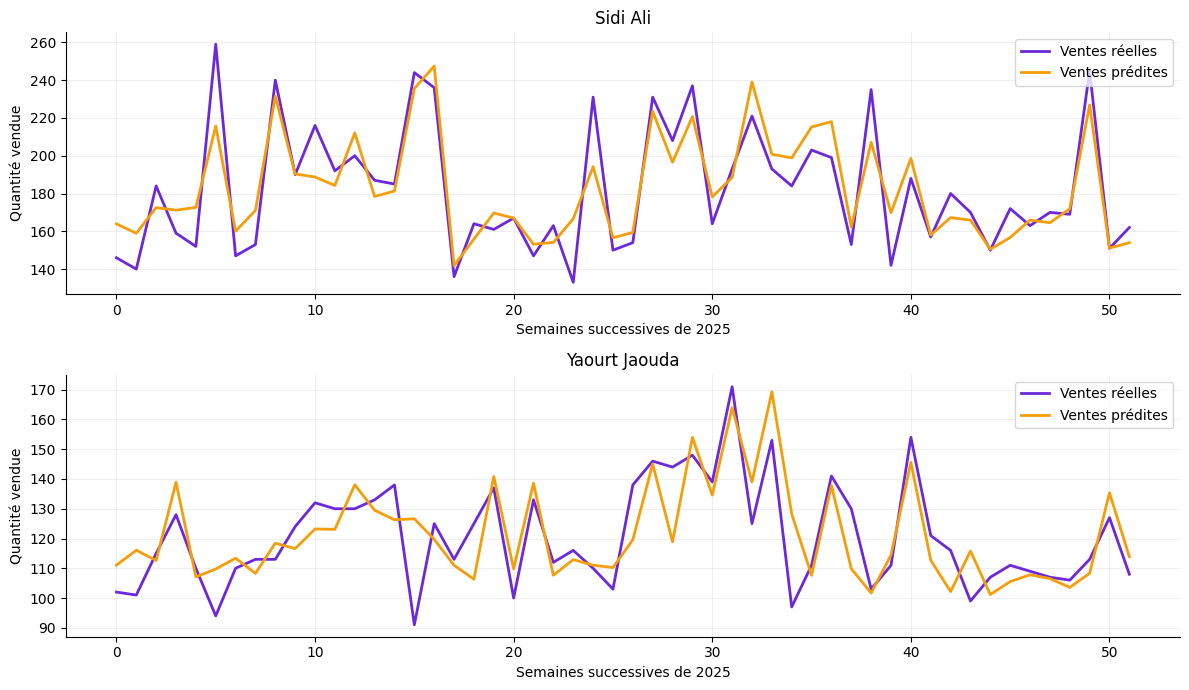


========== ERREUR PAR PRODUIT ==========


,MAE,Ventes_moyennes,Nombre_predictions
produit,,,
Ain Saiss,19.91,271.13,52
Biscuits Merendina,15.76,263.58,52
Fromage La Vache Qui Rit,14.55,200.06,52
Couscous Dari,14.55,161.46,52
Sidi Ali,12.24,182.23,52
Ciel,12.20,145.31,52
Thé vert Sultan,11.17,185.71,52
Lait UHT Centrale,8.89,103.73,52
Yaourt Jaouda,8.63,120.63,52


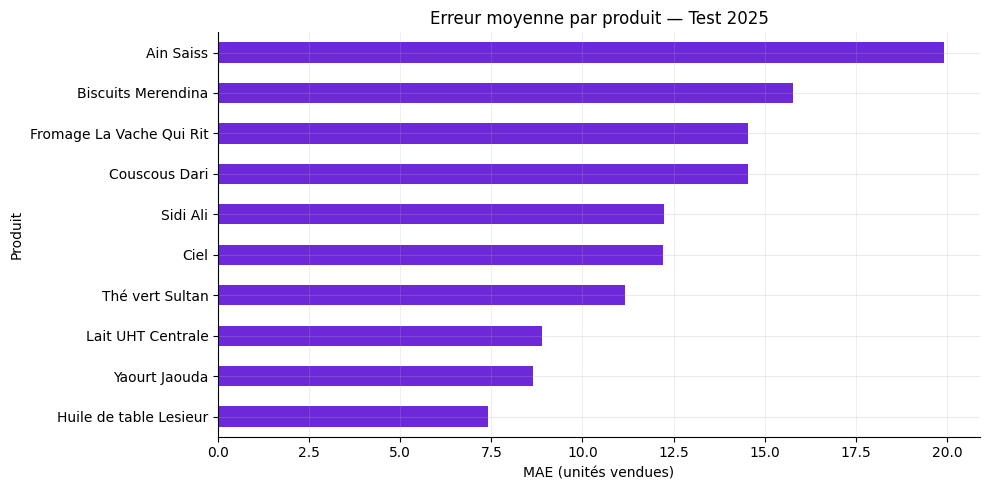


========== IMPORTANCE DES VARIABLES ==========


,Importance
num__moyenne_4_semaines,0.4076
num__promotion,0.1966
num__ventes_s1,0.1042
num__prix,0.0452
num__nombre_lots,0.0421
num__ventes_s3,0.0296
cat__produit_Fromage La Vache Qui Rit,0.0248
cat__produit_Biscuits Merendina,0.0179
num__mois_num,0.0152
num__duree_vie_jours,0.0145


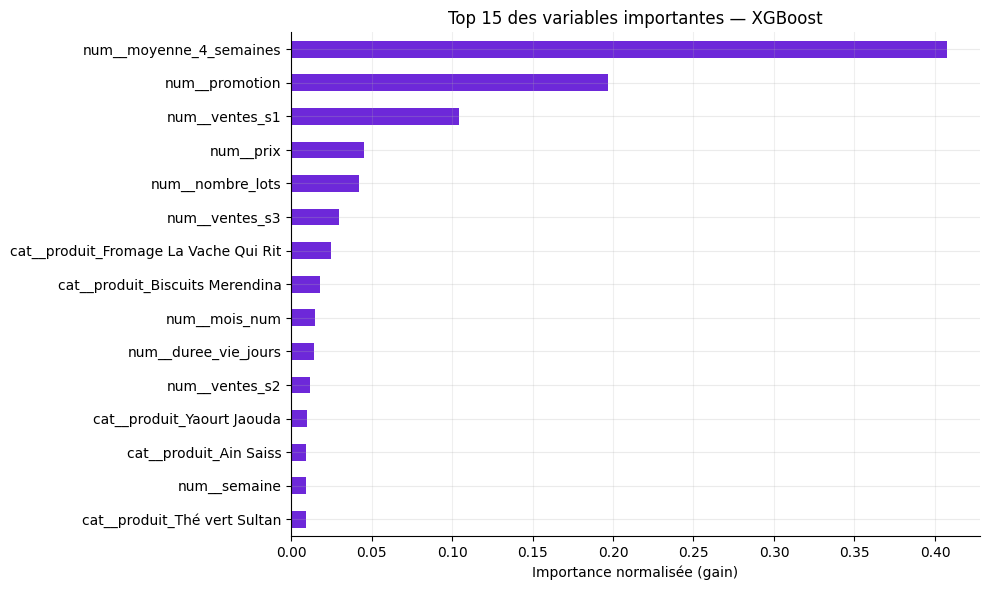


========== BILAN FINAL STOCKJUSTE ==========
Nombre de prédictions : 520
MAE : 12.53
RMSE : 16.69
R² : 0.926

Test final terminé avec succès !


In [40]:
# ============================================================
# 6. TEST FINAL DU MODÈLE XGBOOST — STOCKJUSTE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. PRÉDICTIONS SUR TEST 2025
# ------------------------------------------------------------

pred_test = modele.predict(X_test_xgb)

# ------------------------------------------------------------
# 2. ÉVALUATION ET COMPARAISON DES MODÈLES
# ------------------------------------------------------------

resultats_test = pd.DataFrame({
    'Naïf (S-1)': evaluer(y_test, test_f['ventes_s1']),
    'Moyenne 4 semaines': evaluer(
        y_test, test_f['moyenne_4_semaines']
    ),
    'Ridge': evaluer(y_test, ridge.predict(X_test)),
    'XGBoost (base)': evaluer(
        y_test, modele_base.predict(X_test_xgb)
    ),
    'XGBoost (réglé)': evaluer(y_test, pred_test)
}).T.round(2)

print("\n========== RÉSULTATS SUR TEST 2025 ==========")
display(resultats_test)

# ------------------------------------------------------------
# 3. COMPARAISON VALIDATION VS TEST
# ------------------------------------------------------------

comparaison = pd.DataFrame({
    'Validation': resultats_val.loc['XGBoost (réglé)'],
    'Test': resultats_test.loc['XGBoost (réglé)']
})

print("\n========== VALIDATION VS TEST ==========")
display(comparaison.round(2))

# ------------------------------------------------------------
# 4. GRAPHIQUES : RÉEL VS PRÉDIT ET RÉSIDUS
# ------------------------------------------------------------

y_reel = np.asarray(y_test)
residus = y_reel - pred_test

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Réel vs prédit
ax[0].scatter(
    y_reel,
    pred_test,
    s=18,
    alpha=0.6,
    color='#6D28D9'
)

lim = [
    min(y_reel.min(), pred_test.min()),
    max(y_reel.max(), pred_test.max())
]

ax[0].plot(lim, lim, 'k--', linewidth=1)

ax[0].set_xlabel('Quantité réelle')
ax[0].set_ylabel('Quantité prédite')
ax[0].set_title('Ventes réelles vs prédites — Test 2025')
ax[0].grid(alpha=0.2)

# Distribution des erreurs
ax[1].hist(
    residus,
    bins=30,
    color='#6D28D9',
    alpha=0.8
)

ax[1].axvline(0, color='black', linestyle='--')

ax[1].set_xlabel('Erreur (réel - prédit)')
ax[1].set_ylabel('Fréquence')
ax[1].set_title(
    f'Erreurs | Moyenne : {residus.mean():.2f}'
)
ax[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. ÉVOLUTION DES VENTES PAR PRODUIT
# ------------------------------------------------------------

# Construire un tableau de diagnostic
diagnostic = test_f[
    ['produit', 'annee', 'mois_num', 'semaine']
].copy()

diagnostic['reel'] = y_reel
diagnostic['predit'] = pred_test
diagnostic['erreur_absolue'] = np.abs(
    diagnostic['reel'] - diagnostic['predit']
)

# Sélectionner deux produits existants
produits = ['Sidi Ali', 'Yaourt Jaouda']

# Conserver uniquement les produits présents
produits = [
    p for p in produits
    if p in diagnostic['produit'].unique()
]

if not produits:
    produits = diagnostic['produit'].unique()[:2].tolist()

fig, axes = plt.subplots(
    len(produits),
    1,
    figsize=(12, 3.5 * len(produits)),
    squeeze=False
)

for ax, produit in zip(axes[:, 0], produits):

    d = diagnostic[
        diagnostic['produit'] == produit
    ].sort_values(['annee', 'mois_num', 'semaine'])

    # Axe chronologique selon l'ordre des périodes
    x = np.arange(len(d))

    ax.plot(
        x, d['reel'],
        label='Ventes réelles',
        color='#6D28D9',
        linewidth=2
    )

    ax.plot(
        x, d['predit'],
        label='Ventes prédites',
        color='#F59E0B',
        linewidth=2
    )

    ax.set_title(produit)
    ax.set_ylabel('Quantité vendue')
    ax.set_xlabel('Semaines successives de 2025')
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. ERREUR PAR PRODUIT
# ------------------------------------------------------------

erreur_produit = (
    diagnostic.groupby('produit')
    .agg(
        MAE=('erreur_absolue', 'mean'),
        Ventes_moyennes=('reel', 'mean'),
        Nombre_predictions=('reel', 'size')
    )
    .sort_values('MAE', ascending=False)
)

print("\n========== ERREUR PAR PRODUIT ==========")
display(erreur_produit.round(2))

plt.figure(figsize=(10, 5))

erreur_produit['MAE'].sort_values().plot(
    kind='barh',
    color='#6D28D9'
)

plt.xlabel('MAE (unités vendues)')
plt.ylabel('Produit')
plt.title('Erreur moyenne par produit — Test 2025')
plt.grid(axis='x', alpha=0.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. IMPORTANCE DES VARIABLES XGBOOST
# ------------------------------------------------------------

# Noms des variables après OneHotEncoder
noms_features = preprocessor_xgb.get_feature_names_out()

# Importance par gain
scores = modele.get_booster().get_score(
    importance_type='gain'
)

# XGBoost peut nommer les variables f0, f1, ...
importance = pd.Series({
    nom: scores.get(f'f{i}', scores.get(nom, 0))
    for i, nom in enumerate(noms_features)
})

# Normalisation
if importance.sum() > 0:
    importance = importance / importance.sum()

importance = importance.sort_values(ascending=False)

print("\n========== IMPORTANCE DES VARIABLES ==========")
display(importance.head(15).round(4).to_frame('Importance'))

plt.figure(figsize=(10, 6))

importance.head(15).sort_values().plot(
    kind='barh',
    color='#6D28D9'
)

plt.xlabel('Importance normalisée (gain)')
plt.title('Top 15 des variables importantes — XGBoost')
plt.grid(axis='x', alpha=0.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. RÉSUMÉ FINAL
# ------------------------------------------------------------

print("\n========== BILAN FINAL STOCKJUSTE ==========")

print("Nombre de prédictions :", len(pred_test))
print("MAE :", round(mean_absolute_error(y_reel, pred_test), 2))
print("RMSE :", round(np.sqrt(mean_squared_error(y_reel, pred_test)), 2))
print("R² :", round(r2_score(y_reel, pred_test), 3))

print("\nTest final terminé avec succès !")

### Conclusion

- Comparez la **MAE du XGBoost** aux références (naïf, moyenne 4 semaines, Ridge) sur le test : c'est le gain réel apporté par le modèle.
- Vérifiez l'écart **validation → test** : s'il est faible, le modèle généralise bien.
- Regardez l'erreur **par produit** : un produit nettement moins bien prédit mérite une analyse.
- **Limites** : dataset simulé, 10 produits seulement ; le modèle ne peut pas prédire un produit absent de l'entraînement.

---
# 7. Sauvegarde du modèle

On sauvegarde, dans le **même dossier que ce notebook**, un seul fichier `modele_xgb.joblib` contenant tout ce qu'il faut pour refaire une prédiction plus tard :
- le **modèle** XGBoost (celui évalué au test),
- le **preprocessing ajusté** (encodage des produits),
- la **liste ordonnée des variables** et la liste des **produits connus**,
- les hyperparamètres, les métriques et les versions des bibliothèques.

> Les versions de `xgboost`, `scikit-learn` et `pandas` utilisées ici doivent être **les mêmes** dans le backend (`requirements.txt`).

In [41]:
import joblib
from pathlib import Path
from sklearn.pipeline import Pipeline

# 1. Créer un pipeline complet
pipeline_final = Pipeline([
    ('preprocessing', preprocessor_xgb),
    ('modele', modele)
])

# Le preprocessing et le modèle sont déjà entraînés.
# Ne pas refaire fit() ici.

# 2. Créer le dossier de sauvegarde
DOSSIER = Path("models")
DOSSIER.mkdir(parents=True, exist_ok=True)

# 3. Enregistrer le modèle retenu
CHEMIN_MODELE = DOSSIER / "stockjuste_xgboost.pkl"

joblib.dump(pipeline_final, CHEMIN_MODELE)

print("Modèle XGBoost optimisé enregistré avec succès !")
print("Fichier :", CHEMIN_MODELE.resolve())

# 4. Vérifier le chargement du modèle
pipeline_charge = joblib.load(CHEMIN_MODELE)

# 5. Tester sur les 5 premières lignes du Test
predictions = pipeline_charge.predict(X_test.head(5))

print("\nPrédictions :", predictions.round(2))
print("Valeurs réelles :", y_test.head(5).values)

# Vérifier que les prédictions sont identiques
assert (
    abs(predictions - modele.predict(X_test_xgb[:5])) < 1e-5
).all()

print("\nVérification réussie : modèle prêt pour l'intégration !")

Modèle XGBoost optimisé enregistré avec succès !
Fichier : C:\Users\Hp\StokeJuste\backend\app\features\prediction\notebook\models\stockjuste_xgboost.pkl

Prédictions : [235.61 231.17 133.38 138.01 192.41]
Valeurs réelles : [220 230 136 130 204]

Vérification réussie : modèle prêt pour l'intégration !


In [1]:
import joblib

# Charger le pipeline enregistré
pipeline = joblib.load("models/stockjuste_xgboost.pkl")

# Récupérer les features attendues
features = pipeline.feature_names_in_.tolist()

print("Nombre de features :", len(features))

print("\nFeatures attendues par le modèle :")

for i, feature in enumerate(features, start=1):
    print(f"{i}. {feature}")

Nombre de features : 14

Features attendues par le modèle :
1. produit
2. ventes_s1
3. ventes_s2
4. ventes_s3
5. ventes_s4
6. promotion
7. prix
8. nombre_lots
9. annee
10. mois_num
11. semaine
12. moyenne_4_semaines
13. tendance
14. duree_vie_jours
